In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Gaussian random fields
$u(x)$ is a Gaussian random variable with mean 0 and variance 1 at each point $x$. However, the values of $u$ at any two points $x_1$ and $x_2$ are dependent. Their dependence is characterised by the covariance function ${\sf Cov}(x_1,x_2)$ that depends only on the distance $h:=\|x_2-x_1\|$. 

We consider the covariance function $\exp\left(-\frac{\|h\|^2}{2l^2}\right)$, where $l$ is the correlation length parameter.

We use Algorithm 1 from here: https://inria.hal.science/hal-01414707v2/document

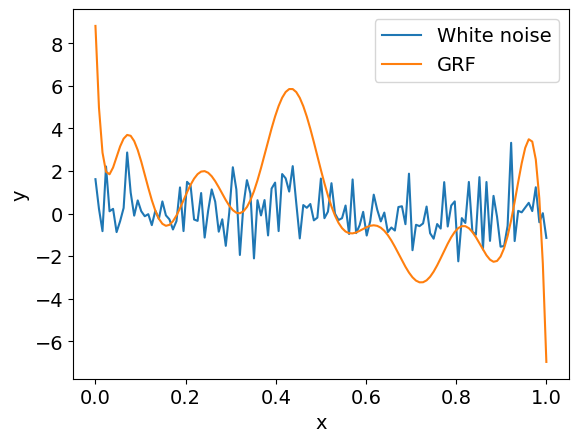

In [3]:
# Generate samples of Gaussian random fields on [0,1]
# with the correlation length parameter l = 0.2.
l = 0.2
Nx = 128
xmax = 1
xmin = 0
x = np.linspace(xmin,xmax,Nx+1)
from scipy.linalg import toeplitz
aux = np.exp(-0.5*(x**2)/(l**2))
Cov = toeplitz(aux,aux) # args = first col, first row
E,V = np.linalg.eig(Cov)
ind = np.argwhere(np.real(E)>1e-8)
V = np.real(V)
Cov_sqrt = V[:,ind]@np.diag(np.sqrt(np.real(E[ind])))@np.transpose(V[:,ind])
w = np.random.normal(loc=0, scale=1, size=Nx+1) # loc = mean, scale = STD
u = Cov_sqrt@w

plt.rcParams.update({'font.size': 14})
plt.plot(x,w,label = "White noise")
plt.plot(x,u.squeeze(),label = "GRF")
plt.xlabel('x')
plt.ylabel('y')
plt.legend()

Text(0, 0.5, 'u')

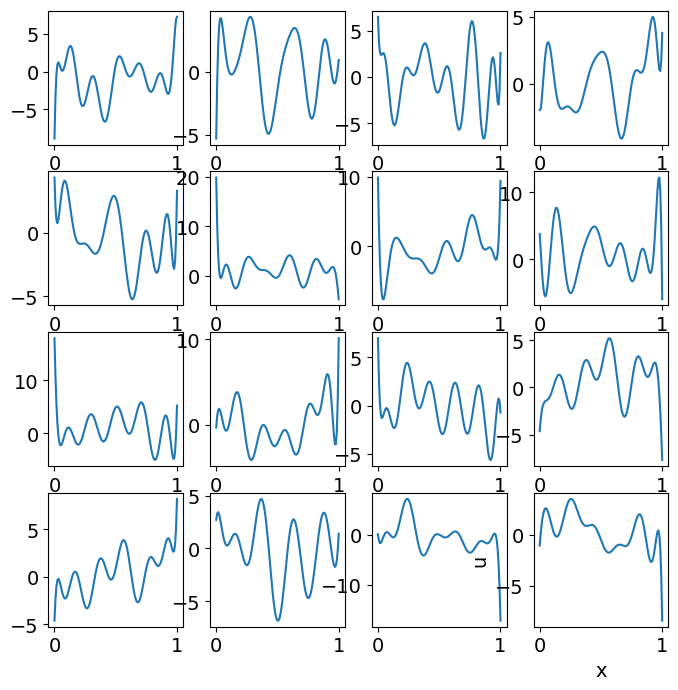

In [4]:
# Generate multiple samples with different noise realizations
Nsamples = 16
fig, ax = plt.subplots(4,4, figsize=(8,8))
for j in range(Nsamples):
    w = np.random.normal(loc=0, scale=1, size=Nx+1) # loc = mean, scale = STD
    u = Cov_sqrt@w
    row = j // 4  # Integer division to get the row index
    col = j % 4   # Modulo to get the column index
    ax[row,col].plot(x,u.squeeze())
plt.xlabel("x")
plt.ylabel("u")


Text(0, 0.5, 'u')

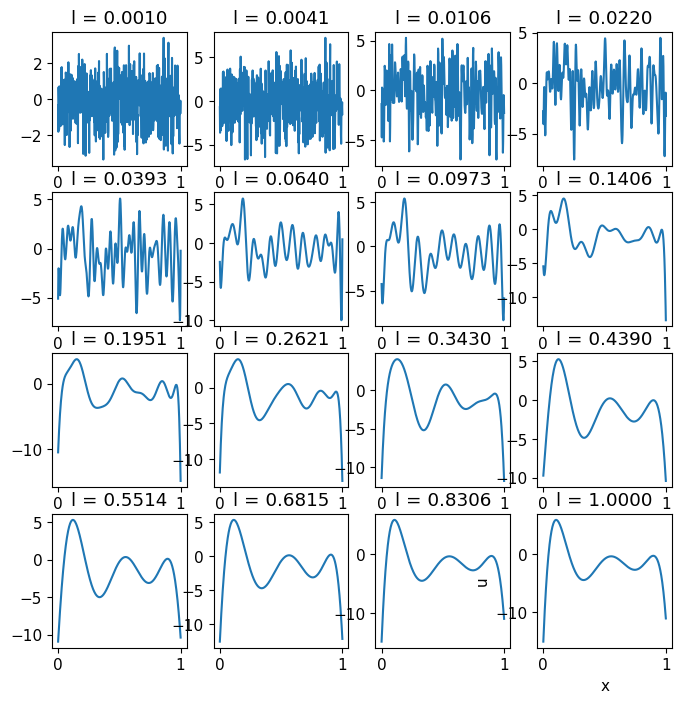

In [21]:
# generate samples with different correlation length l
Nsamples = 16
Nx = 512
x = np.linspace(xmin,xmax,Nx+1)
w = np.random.normal(loc=0, scale=1, size=Nx+1) # loc = mean, scale = STD
lvals = (np.linspace(0.1,1,Nsamples))**3
plt.rcParams.update({'font.size': 11})
fig, ax = plt.subplots(4,4, figsize=(8,8))
for j in range(Nsamples):
    l = lvals[j]
    aux = np.exp(-0.5*(x**2)/(l**2))
    Cov = toeplitz(aux,aux) # args = first col, first row
    E,V = np.linalg.eig(Cov)
    ind = np.argwhere(np.real(E)>1e-8)
    V = np.real(V)
    Cov_sqrt = V[:,ind]@np.diag(np.sqrt(np.real(E[ind])))@np.transpose(V[:,ind])
    u = Cov_sqrt@w
    row = j // 4  # Integer division to get the row index
    col = j % 4   # Modulo to get the column index
    ax[row,col].plot(x,u.squeeze())
    ax[row,col].set_title(f"l = {l:.4f}")
plt.xlabel("x")
plt.ylabel("u")
